# FOVL assignment: word embeddings for Indian languages

This notebook solves the FOVL assignment step by step. Every code cell has a short note above it with three parts.

- What we do in this step.
- Why we need this step.
- How the code does it.

The goal in one line. Teach the computer the meaning of words in 7 Indian languages (Gujarati, Hindi, Marathi, Punjabi, Tamil, Telugu and Urdu), using only the IndicCorpV2 text, and then check if the computer thinks the same words are similar as people do.

Files you need next to this notebook

- `fovl_data/data.parquet` from https://huggingface.co/datasets/rony000013/indiccorpV2-5k
- the folder `Word-Similarity-Datasets-for-Indian-Languages` from https://github.com/syedsarfarazakhtar/Word-Similarity-Datasets-for-Indian-Languages

Libraries: numpy, pandas, gensim, scipy, scikit-learn, matplotlib. Everything is trained from scratch. No pre-trained vectors are used.


## Step 1. Load the training text

What. We read the IndicCorpV2 file and list the 7 languages we must cover.

Why. The assignment allows only this corpus for training. The 7 languages are the ones that have a word similarity test set.

How. `pandas.read_parquet` reads the file. It has three columns: `language`, `code` and `text`. There are 5,000 lines for each language. We also make an output folder for the models and results.


In [1]:
import os
import unicodedata
import numpy as np
import pandas as pd
from gensim.models import FastText
from scipy.stats import spearmanr

# 1. Load the IndicCorpV2 data
data = pd.read_parquet("fovl_data/data.parquet")
print("Total lines:", len(data))
print("Languages in corpus:", data.code.nunique())

languages = {
    "gu": "Gujarati",
    "hi": "Hindi",
    "mr": "Marathi",
    "pa": "Punjabi",
    "ta": "Tamil",
    "te": "Telugu",
    "ur": "Urdu"
}

ws_folder = "Word-Similarity-Datasets-for-Indian-Languages"
out_folder = "fovl_output"
os.makedirs(out_folder, exist_ok=True)

Total lines: 118243
Languages in corpus: 24


## Step 2. Clean the text and cut it into words

What. We turn every line into a list of words.

Why. A word embedding model learns from words that sit near each other, so it needs clean word lists, not raw lines.

How.
- `unicodedata.normalize("NFC", ...)` makes sure the same letter is always stored the same way. In Indian scripts one letter can be typed in two ways, and without this step the model would see two different words.
- We remove punctuation, symbols, numbers and English (ASCII) letters by checking the Unicode category of each character.
- We do not use the regex `\w` here, because it treats vowel signs (matras like ा, ि) as breaks and cuts words into pieces.


In [2]:
# 2. Clean the text and split it into words
def clean(text):
    text = unicodedata.normalize("NFC", text).replace("​", "")
    chars = []
    for ch in text:
        if unicodedata.category(ch)[0] in "PSZN" or ch.isascii():
            chars.append(" ")
        else:
            chars.append(ch)
    return "".join(chars).split()

sentences = {}

for code, name in languages.items():
    lines = data[data.code == code].text
    sentences[code] = [clean(line) for line in lines]
    tokens = sum(len(s) for s in sentences[code])
    types = len(set(w for s in sentences[code] for w in s))
    print(name, "| lines:", len(lines), "| tokens:", tokens, "| unique words:", types)

print("Example:", sentences["hi"][0][:12])

Gujarati | lines: 5000 | tokens: 201036 | unique words: 37541


Hindi | lines: 5000 | tokens: 279852 | unique words: 24245


Marathi | lines: 5000 | tokens: 202624 | unique words: 44206


Punjabi | lines: 5000 | tokens: 270046 | unique words: 25454


Tamil | lines: 5000 | tokens: 166263 | unique words: 53943


Telugu | lines: 5000 | tokens: 170152 | unique words: 46596


Urdu | lines: 5000 | tokens: 357737 | unique words: 28674
Example: ['लोगों', 'को', 'बिलों', 'संबंधी', 'सुविधा', 'देना', 'ही', 'उनका', 'काम']


## Step 3. Load the word similarity test sets

What. For each language we read the word pairs and the human score for each pair.

Why. These scores are how we test the model. People gave each pair a score from 0 to 10, for example tiger and cat get about 7.

How.
- The Hindi file uses commas, the other files use tabs.
- In the Marathi file, 149 of the 253 pairs have no human score. We keep them (we still must give their embeddings), but we mark the score as `None` and skip them when we compute Spearman.
- The human scores are used only for testing, never for training.


In [3]:
# 3. Load the word similarity datasets
def load_pairs(name):
    sep = "," if name == "Hindi" else "\t"
    pairs = []
    with open(f"{ws_folder}/{name}-WS.txt", encoding="utf-8") as f:
        for line in f:
            if line.strip() == "":
                continue
            parts = line.rstrip("\r\n").split(sep)
            score = float(parts[2]) if parts[2].strip() != "" else None
            pairs.append((parts[0].strip(), parts[1].strip(), score))
    return pairs

word_pairs = {}

for code, name in languages.items():
    word_pairs[code] = load_pairs(name)
    scored = [p for p in word_pairs[code] if p[2] is not None]
    print(name, "| pairs:", len(word_pairs[code]), "| pairs with human score:", len(scored))

print("Example:", word_pairs["hi"][:3])

Gujarati | pairs: 163 | pairs with human score: 163
Hindi | pairs: 235 | pairs with human score: 235
Marathi | pairs: 253 | pairs with human score: 104
Punjabi | pairs: 143 | pairs with human score: 143
Tamil | pairs: 97 | pairs with human score: 97
Telugu | pairs: 111 | pairs with human score: 111
Urdu | pairs: 100 | pairs with human score: 100
Example: [('मोहब्बत', 'सेक्स', 6.8), ('बाघ', 'बिल्ली', 7.0), ('किताब', 'कागज़', 7.6)]


## Step 4 and 5. Train one FastText model per language

What. We train a FastText skip-gram model with 300 dimensions for every language.

Why FastText. FastText learns a vector for every word and also for small pieces of the word (character n-grams, here 3 to 6 letters). So a word never seen in training (OOV) still gets a good vector built from its pieces. This is the OOV handling the assignment asks for. Indian languages add many endings to words (घर, घरों, घरवाले), so pieces help a lot.

Why these settings. We tried many settings and kept the best on the public test sets:
- `window = 8`: look at 8 words on each side, so we catch more meaning from a small corpus.
- `min_count = 1`: keep even rare words, because 5,000 lines is very small.
- `bucket = 100000`: number of slots for the n-gram vectors. It keeps the model small and was as good as the default.
- `sg = 1` (skip-gram) was much better than CBOW on this small data.
- `workers = 1` and `seed = 42` so the result is the same every time you run.

How. gensim `FastText` does the training. We save each model to a file and free the memory before the next language.


In [4]:
# 4. Hyperparameters
d = 300
window = 8
min_count = 1
min_n = 3
max_n = 6
negative = 10
epochs = 20
bucket = 100000

# 5. Train one FastText skip-gram model per language
for code, name in languages.items():
    model = FastText(
        sentences=sentences[code],
        vector_size=d,
        window=window,
        min_count=min_count,
        min_n=min_n,
        max_n=max_n,
        sg=1,
        negative=negative,
        epochs=epochs,
        bucket=bucket,
        workers=1,
        seed=42
    )
    model.save(f"{out_folder}/{name}-fasttext.model")
    print(name, "| words learned:", len(model.wv.key_to_index), "| vector size:", model.wv.vector_size)
    del model

Gujarati | words learned: 37541 | vector size: 300


Hindi | words learned: 24245 | vector size: 300


Marathi | words learned: 44206 | vector size: 300


Punjabi | words learned: 25454 | vector size: 300


Tamil | words learned: 53943 | vector size: 300


Telugu | words learned: 46596 | vector size: 300


Urdu | words learned: 28674 | vector size: 300


## Step 6. A vector for any word, even an OOV word

What. `get_vector` returns a 300 number vector for any word.

Why. The private test will have words we have never seen. We must still give a vector.

How.
- If the word is in the model, FastText gives its learned vector.
- If it is not, FastText adds up the vectors of its character n-grams.
- If the entry has two words (like `कुटुंब नियोजन`), we take the average of the two word vectors.
- `cosine_similarity` measures the angle between two vectors. 1 means same direction (very similar), 0 means not related.

We test it on `कीबोर्ड` (keyboard), which is not in the Hindi training text.


In [5]:
# 6. Load the models and get a vector for any word (also OOV words)
models = {}

for code, name in languages.items():
    models[code] = FastText.load(f"{out_folder}/{name}-fasttext.model")

def get_vector(code, word):
    model = models[code]
    parts = clean(word)
    if len(parts) == 0:
        parts = [word]
    vectors = [model.wv[p] for p in parts]
    return np.mean(vectors, axis=0)

def cosine_similarity(a, b):
    return np.dot(a, b) / (
        np.linalg.norm(a) * np.linalg.norm(b) + 1e-12
    )

test_word = "कीबोर्ड"
print(test_word, "in Hindi training words:", test_word in models["hi"].wv.key_to_index)
print("Vector shape:", get_vector("hi", test_word).shape)
print("Nearest words:", models["hi"].wv.most_similar(test_word, topn=5))

कीबोर्ड in Hindi training words: False
Vector shape: (300,)
Nearest words: [('बिलबोर्ड', 0.9310944676399231), ('डेशबोर्ड', 0.9273094534873962), ('डेसबोर्ड', 0.9176804423332214), ('बोर्ड', 0.9093867540359497), ('रिंगबोर्ड', 0.8990628719329834)]


## Step 7. How many test words did the model see in training

What. For each language we count the test words, how many are missing from the model vocabulary (OOV), and how many pairs have at least one OOV word.

Why. The assignment asks us to report vocabulary coverage and OOV numbers for each language. It also helps to explain why some languages score lower.

How. We compare the test words with `model.wv.key_to_index`, which is the list of words the model learned.


In [6]:
# 7. Vocabulary coverage and OOV statistics
coverage_rows = []

for code, name in languages.items():
    corpus_words = set(w for s in sentences[code] for w in s)
    model_words = models[code].wv.key_to_index

    test_words = set()
    for w1, w2, score in word_pairs[code]:
        test_words.add(w1)
        test_words.add(w2)

    oov_words = [w for w in test_words if w not in model_words]
    oov_pairs = [p for p in word_pairs[code] if p[0] not in model_words or p[1] not in model_words]
    coverage = 100 * (len(test_words) - len(oov_words)) / len(test_words)

    coverage_rows.append([name, len(model_words), len(test_words), len(oov_words), round(coverage, 1), len(oov_pairs)])

coverage_table = pd.DataFrame(
    coverage_rows,
    columns=["language", "model_vocab", "test_words", "oov_words", "coverage_%", "pairs_with_oov"]
)
print(coverage_table.to_string(index=False))

language  model_vocab  test_words  oov_words  coverage_%  pairs_with_oov
Gujarati        37541         221         23        89.6              23
   Hindi        24245         318         39        87.7              57
 Marathi        44206         337         66        80.4              70
 Punjabi        25454         206         22        89.3              25
   Tamil        53943         137         37        73.0              39
  Telugu        46596         160         48        70.0              52
    Urdu        28674         146         25        82.9              24


## Step 8. Cosine similarity and Spearman correlation

What. We score every test pair with cosine similarity and compare the model scores with the human scores.

Why. Spearman correlation checks if the model puts the pairs in the same order as people. It does not care about the exact numbers, only the ranking. 1 is perfect, 0 is no relation.

How.
- Formula for cosine: s(wi, wj) = (vi · vj) / (‖vi‖ ‖vj‖)
- `spearmanr` from scipy gives ρ for each language.
- The final score is the macro average: the simple mean of the 7 ρ values.


In [7]:
# 8. Cosine similarity and Spearman correlation per language
results = {}

for code, name in languages.items():
    model_scores = []
    human_scores = []

    for w1, w2, score in word_pairs[code]:
        if score is None:
            continue
        sim = cosine_similarity(get_vector(code, w1), get_vector(code, w2))
        model_scores.append(sim)
        human_scores.append(score)

    rho = spearmanr(model_scores, human_scores).correlation
    results[name] = rho
    print(name, "| pairs used:", len(human_scores), "| Spearman: %.4f" % rho)

macro = np.mean(list(results.values()))
print("\nMacro-average Spearman: %.4f" % macro)

Gujarati | pairs used: 163 | Spearman: 0.4603
Hindi | pairs used: 235 | Spearman: 0.3226
Marathi | pairs used: 104 | Spearman: 0.3974


Punjabi | pairs used: 143 | Spearman: 0.3488
Tamil | pairs used: 97 | Spearman: 0.3020
Telugu | pairs used: 111 | Spearman: 0.2250
Urdu | pairs used: 100 | Spearman: 0.2995

Macro-average Spearman: 0.3365


## Step 9. Save the embeddings in the required format

What. For every language we save an array of shape (N, 2, 300) and a vocabulary file.

Why. This is the submission format. N is the number of pairs in the test file, the 2 is the two words in a pair, and 300 is the vector size. The order of pairs is the same as in the original file.

How.
- `{name}-WS-embeddings.npy` holds the (N, 2, 300) array.
- `{name}-vocabulary.txt` lists every test word with an index, and `{name}-vocab-embeddings.npy` has the vector of each word in the same order. Row i of the npy is the vector of word i in the txt.


In [8]:
# 9. Save the embeddings (N, 2, 300) and the vocabulary files
for code, name in languages.items():
    pairs = word_pairs[code]
    embeddings = np.zeros((len(pairs), 2, d), dtype=np.float32)

    for i, (w1, w2, score) in enumerate(pairs):
        embeddings[i, 0] = get_vector(code, w1)
        embeddings[i, 1] = get_vector(code, w2)

    np.save(f"{out_folder}/{name}-WS-embeddings.npy", embeddings)

    vocab = []
    for w1, w2, score in pairs:
        if w1 not in vocab:
            vocab.append(w1)
        if w2 not in vocab:
            vocab.append(w2)

    vocab_vectors = np.array([get_vector(code, w) for w in vocab], dtype=np.float32)
    np.save(f"{out_folder}/{name}-vocab-embeddings.npy", vocab_vectors)

    with open(f"{out_folder}/{name}-vocabulary.txt", "w", encoding="utf-8") as f:
        for i, w in enumerate(vocab):
            f.write(f"{i}\t{w}\n")

    print(name, "| pair embeddings:", embeddings.shape, "| vocabulary:", vocab_vectors.shape)

Gujarati | pair embeddings: (163, 2, 300) | vocabulary: (221, 300)
Hindi | pair embeddings: (235, 2, 300) | vocabulary: (318, 300)
Marathi | pair embeddings: (253, 2, 300) | vocabulary: (337, 300)
Punjabi | pair embeddings: (143, 2, 300) | vocabulary: (206, 300)
Tamil | pair embeddings: (97, 2, 300) | vocabulary: (137, 300)
Telugu | pair embeddings: (111, 2, 300) | vocabulary: (160, 300)
Urdu | pair embeddings: (100, 2, 300) | vocabulary: (146, 300)


## Step 10. Look at the words in a picture (t-SNE)

What. We squeeze 100 test words per language from 300 numbers down to 2, and draw them.

Why. We can not see 300 dimensions. t-SNE keeps words that are close in 300 dimensions also close on the 2D picture, so we can check if similar words sit together.

How. `sklearn.manifold.TSNE` with perplexity 15. We pick the first 100 different words from the test file. We set a font for each script so the words show up. Each picture is also saved as a PNG for the report.


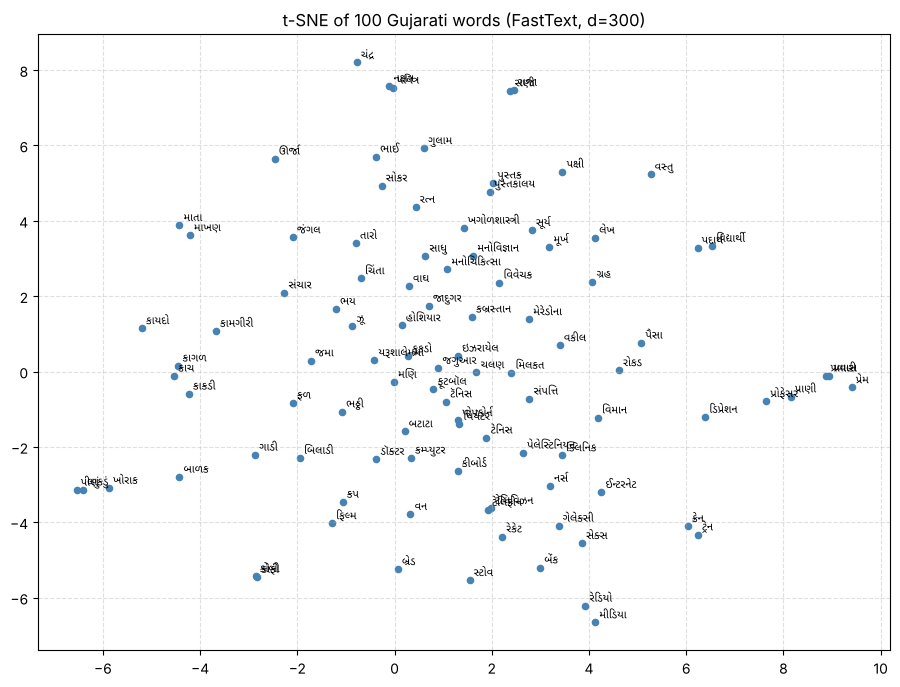

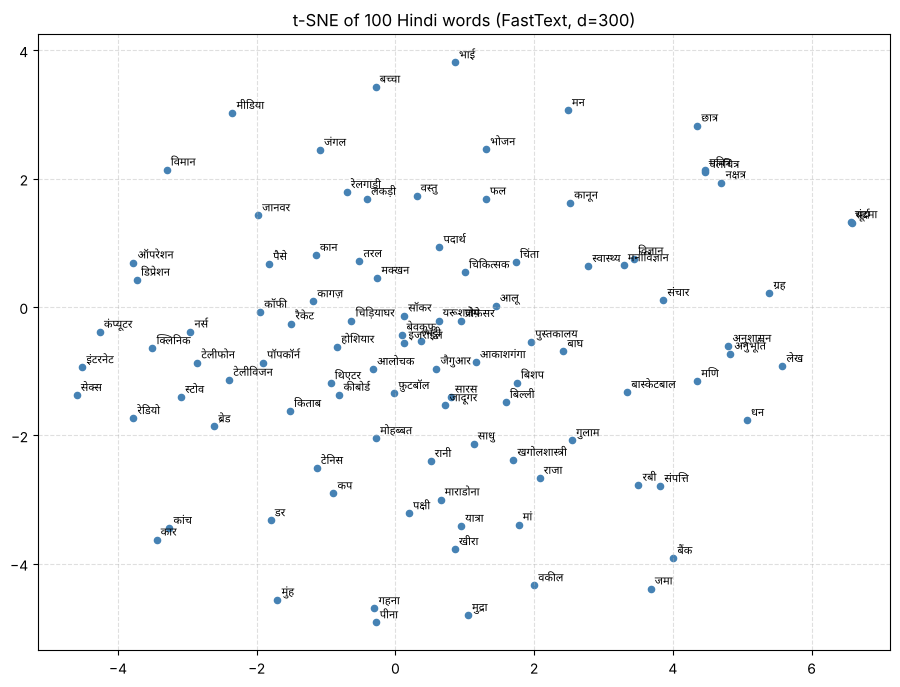

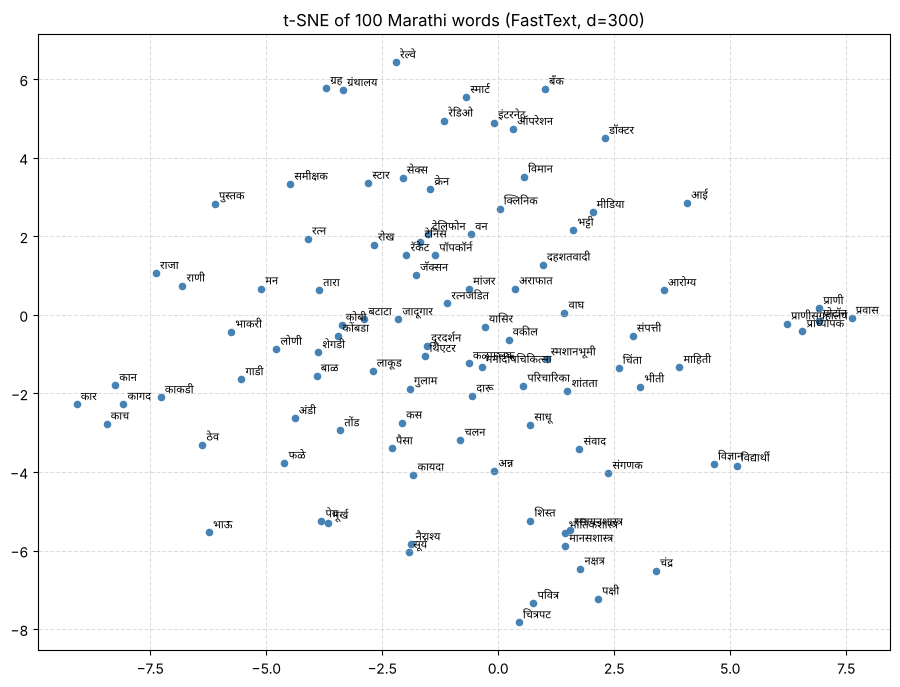

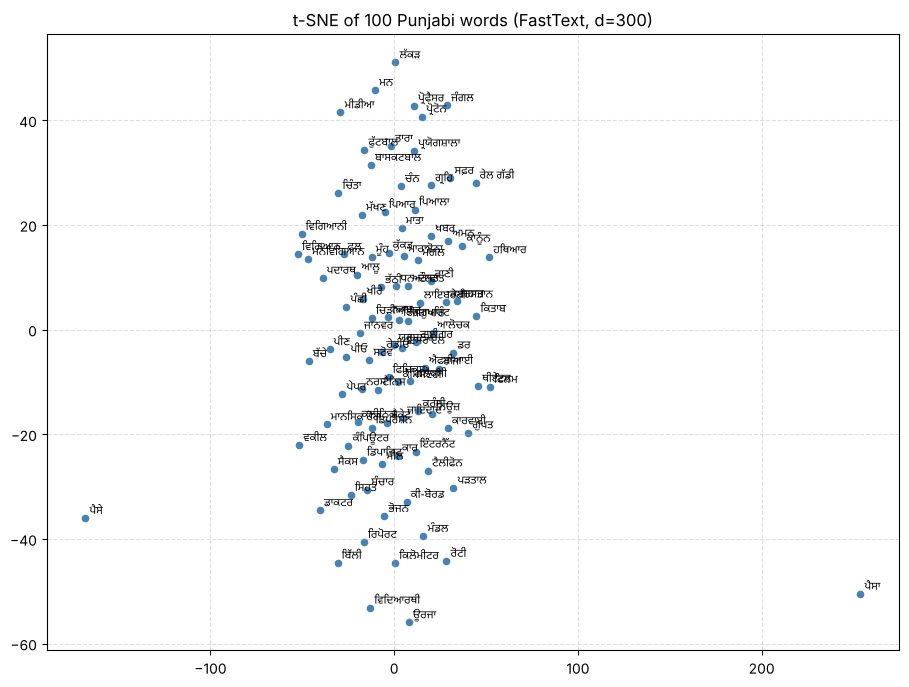

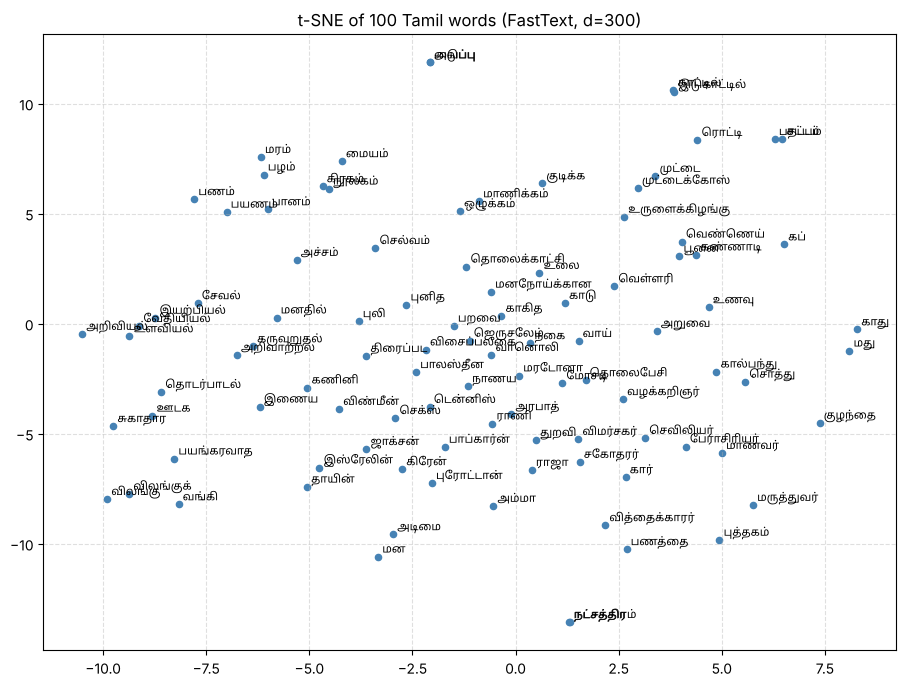

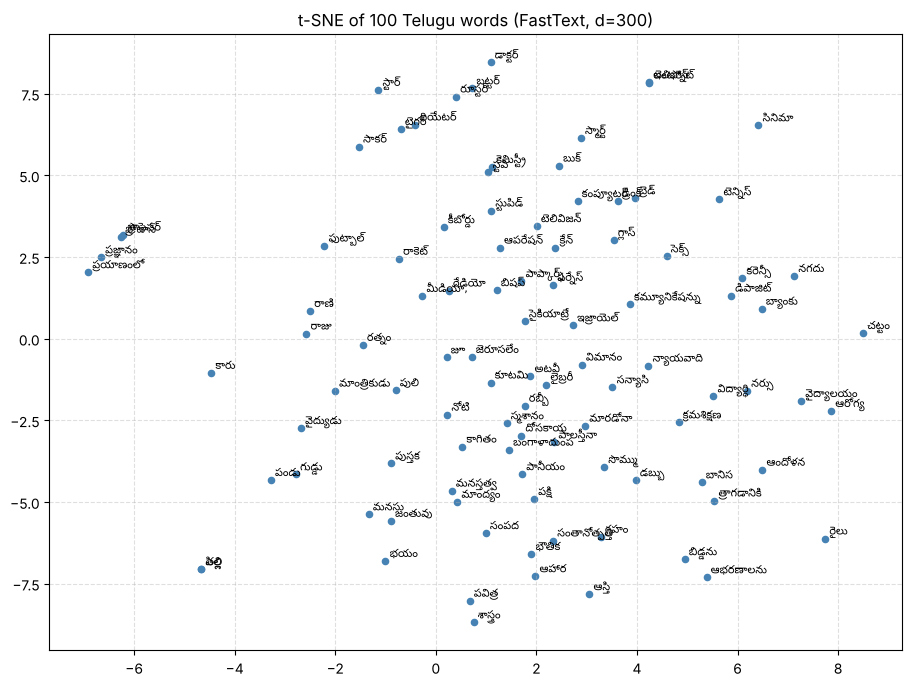

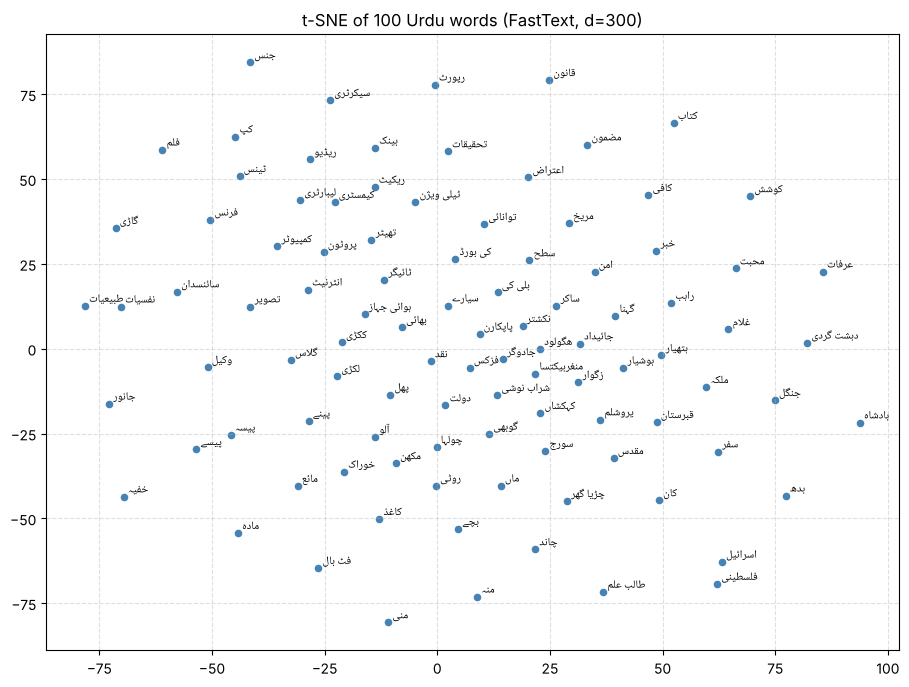

In [9]:
# 10. t-SNE plot of 100 words per language
import logging
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

fonts = {
    "gu": ["Noto Sans Gujarati", "Gujarati Sangam MN"],
    "hi": ["Noto Sans Devanagari", "Kohinoor Devanagari"],
    "mr": ["Noto Sans Devanagari", "Kohinoor Devanagari"],
    "pa": ["Noto Sans Gurmukhi", "Gurmukhi MN"],
    "ta": ["Noto Sans Tamil", "Tamil Sangam MN"],
    "te": ["Noto Sans Telugu", "Telugu Sangam MN"],
    "ur": ["Noto Naskh Arabic", "Geeza Pro"]
}

for code, name in languages.items():
    words = []
    for w1, w2, score in word_pairs[code]:
        for w in [w1, w2]:
            if w != "" and w not in words and len(words) < 100:
                words.append(w)

    X = np.array([get_vector(code, w) for w in words])
    coords = TSNE(n_components=2, perplexity=15, random_state=42, init="pca").fit_transform(X)

    plt.figure(figsize=(11, 8))
    plt.scatter(coords[:, 0], coords[:, 1], color="steelblue", s=20)
    for i, w in enumerate(words):
        plt.annotate(w, (coords[i, 0], coords[i, 1]), fontsize=8,
                     xytext=(3, 3), textcoords="offset points",
                     fontfamily=fonts[code] + ["DejaVu Sans"])
    plt.title(f"t-SNE of 100 {name} words (FastText, d=300)")
    plt.grid(True, linestyle="--", alpha=0.4)
    plt.savefig(f"{out_folder}/tsne-{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

## Step 11. Good and bad examples

What. For each language we show 2 pairs where the model agrees with people and 2 pairs where it does not.

Why. The report must explain where the model is right and where it is wrong, with examples.

How. We turn both the human score and the cosine into a rank between 0 and 1. The gap between the two ranks tells how wrong the model is for that pair. Small gap is good, big gap is bad. The table is also saved as CSV.


In [10]:
# 11. Good and bad predictions (rank of human score against rank of model score)
analysis = []

for code, name in languages.items():
    rows = []
    for w1, w2, score in word_pairs[code]:
        if score is None or w1 == w2:
            continue
        sim = cosine_similarity(get_vector(code, w1), get_vector(code, w2))
        rows.append([name, w1, w2, score, round(float(sim), 3)])

    table = pd.DataFrame(rows, columns=["language", "word1", "word2", "human", "cosine"])
    table["human_rank"] = table.human.rank(pct=True).round(2)
    table["model_rank"] = table.cosine.rank(pct=True).round(2)
    table["gap"] = (table.human_rank - table.model_rank).abs().round(2)
    table = table.sort_values("gap")
    analysis.append(table.head(2))
    analysis.append(table.tail(2))

analysis = pd.concat(analysis)
analysis.to_csv(f"{out_folder}/analysis-examples.csv", index=False)
print(analysis.to_string(index=False))

language     word1          word2  human  cosine  human_rank  model_rank  gap
Gujarati    ડૉક્ટર           નર્સ  9.000   0.614        0.86        0.86 0.00
Gujarati    થિયેટર         ઇતિહાસ  7.750   0.448        0.50        0.50 0.00
Gujarati      મંગળ      વૈજ્ઞાનિક  9.000   0.240        0.86        0.10 0.76
Gujarati     વિલંબ        જાતિવાદ  0.000   0.567        0.03        0.79 0.76
   Hindi  कंप्यूटर     प्रयोगशाला  7.400   0.480        0.75        0.76 0.01
   Hindi  कंप्यूटर      सॉफ्टवेयर  8.800   0.725        0.99        0.98 0.01
   Hindi      पैसे           बैंक  8.200   0.263        0.95        0.15 0.80
   Hindi    अवलोकन    आर्किटेक्चर  3.200   0.726        0.16        0.99 0.83
 Marathi      रत्न       रत्नजडित  9.375   0.834        0.99        0.99 0.00
 Marathi      ग्रह खगोलशास्त्रज्ञ  8.000   0.535        0.83        0.83 0.00
 Marathi   टेलिफोन          संवाद  9.000   0.205        0.96        0.09 0.87
 Marathi    अराफात         जॅक्सन  0.000   0.724        0.03    

## Step 12. Embeddings for a new file (for the private test)

What. `embed_file` reads any word pair file and gives back the (N, 2, 300) array.

Why. The final ranking uses a private test set. This function makes the embeddings for it, also for OOV words.

How. It finds the separator (tab or comma) by itself, calls `get_vector` for both words, and saves the npy file. We check it on the Tamil file and get the same array as in Step 9. Then we try a few made up word forms that are not in the training text, and they still get a real vector.


In [11]:
# 12. Make embeddings for a new word-pair file (used for the private test)
def embed_file(file_path, code, save_path):
    pairs = []
    with open(file_path, encoding="utf-8") as f:
        for line in f:
            if line.strip() == "":
                continue
            sep = "\t" if "\t" in line else ","
            parts = line.rstrip("\r\n").split(sep)
            pairs.append((parts[0].strip(), parts[1].strip()))

    output = np.zeros((len(pairs), 2, d), dtype=np.float32)
    for i, (w1, w2) in enumerate(pairs):
        output[i, 0] = get_vector(code, w1)
        output[i, 1] = get_vector(code, w2)

    np.save(save_path, output)
    return output

check = embed_file(f"{ws_folder}/Tamil-WS.txt", "ta", f"{out_folder}/check-Tamil.npy")
print("Shape:", check.shape)
print("Same as saved file:", np.allclose(check, np.load(f"{out_folder}/Tamil-WS-embeddings.npy")))

new_words = [("hi", "कम्प्यूटरवाला"), ("mr", "संगणकवाल्यांनी"), ("pa", "ਕੰਪਿਊਟਰਾਂ")]
for code, w in new_words:
    print(w, "| in vocab:", w in models[code].wv.key_to_index, "| norm: %.3f" % np.linalg.norm(get_vector(code, w)))

Shape: (97, 2, 300)
Same as saved file: True
कम्प्यूटरवाला | in vocab: False | norm: 2.666
संगणकवाल्यांनी | in vocab: False | norm: 4.470
ਕੰਪਿਊਟਰਾਂ | in vocab: False | norm: 3.800


## What we got and what to remember

- One FastText skip-gram model per language, 300 dimensions, trained only on IndicCorpV2.
- OOV words get vectors from their character n-grams, so no pair is dropped.
- The Spearman value for each language and the macro average are printed in Step 8.
- The corpus is small (about 5,000 lines per language), so the scores are modest. More text would help most.
- Things we tried that did not help: one shared model for all 24 languages, mapping all Indian scripts to Devanagari, CBOW, and removing the top principal components after training.
